# 02 - Khám phá và xử lý dữ liệu Marketing Campaign

Mục tiêu: loại dữ liệu trùng lặp, thay thế giá trị, đổi kiểu dữ liệu và xử lý giá trị thiếu (bài mẫu 1.1.2, bài toán 1, nhiệm vụ 2).

## 1. Load data và chọn cột

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

marketing = doc_csv(can_file('marketing_campaign.csv'))
marketing = marketing.drop(columns=[c for c in marketing.columns if c.startswith('Unnamed')])
marketing['Dt_Customer'] = pd.to_datetime(marketing['Dt_Customer'], dayfirst=True, errors='coerce')
kiem_tra_chat_luong(marketing, 'Marketing Campaign')
display(marketing.head())

cols = ['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome',
        'Dt_Customer', 'Recency', 'NumStorePurchases', 'NumWebVisitsMonth']
data = marketing[cols].copy()
print('Shape sau khi chọn cột:', data.shape)

=== Marketing Campaign ===
Shape: (2240, 29)
Số dòng trùng lặp: 0
Giá trị thiếu theo cột:
Income    24
dtype: int64


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


Shape sau khi chọn cột: (2240, 11)


## 2. Loại bỏ dữ liệu trùng lặp, dòng và cột

In [2]:
print('Trùng lặp trên tất cả cột:', int(data.duplicated().sum()))
print('Trùng lặp nếu bỏ cột ID:', int(data.drop(columns='ID').duplicated().sum()))
data_nodup = data.drop_duplicates()
data_drop_row = data.drop(labels=[1], axis=0)
data_drop_col = data.drop(labels=['Year_Birth'], axis=1)
print('drop_duplicates:', data_nodup.shape, '| drop dòng index 1:', data_drop_row.shape, '| drop cột Year_Birth:', data_drop_col.shape)

Trùng lặp trên tất cả cột: 0
Trùng lặp nếu bỏ cột ID: 201
drop_duplicates: (2240, 11) | drop dòng index 1: (2239, 11) | drop cột Year_Birth: (2240, 10)


## 3. Thay thế giá trị và đổi kiểu dữ liệu

Đề mẫu điền `Income` thiếu bằng 0 rồi đổi sang int. Cách này kéo thấp mean và tạo cột giá trị 0 giả, nên notebook so sánh với điền bằng trung vị.

Teenhome_replaced
has no teen    1158
has teen       1082
Name: count, dtype: int64
int64


,gốc (bỏ NaN),fillna(0),fillna(median)
count,2216.0,2240.0,2240.0
mean,52247.3,51687.5,52238.0
std,25173.1,25609.3,25038.0
min,1730.0,0.0,1730.0
25%,35303.0,34722.0,35538.8
50%,51381.5,51075.0,51381.5
75%,68522.0,68289.8,68289.8
max,666666.0,666666.0,666666.0


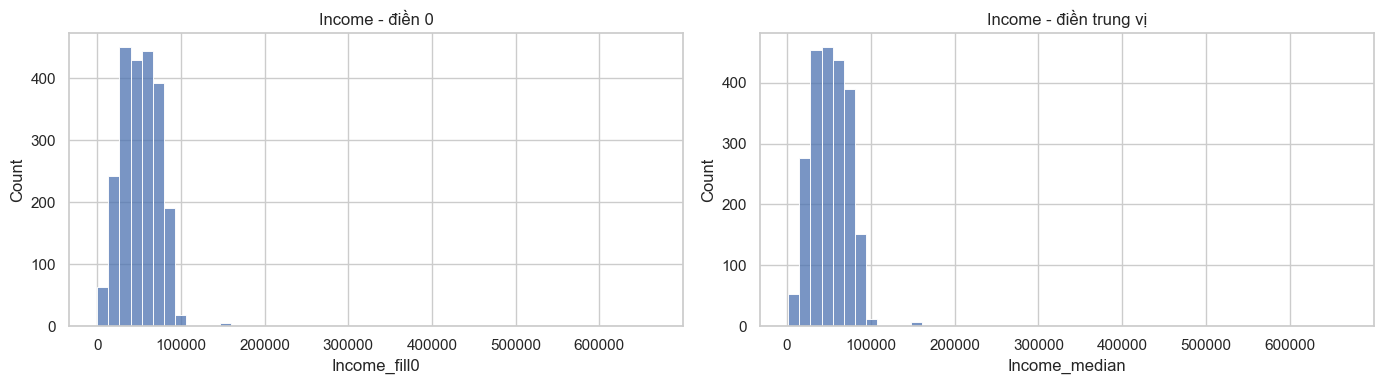

In [3]:
data['Teenhome_replaced'] = data['Teenhome'].replace({0: 'has no teen', 1: 'has teen', 2: 'has teen'})
print(data['Teenhome_replaced'].value_counts())

data['Income_fill0'] = data['Income'].fillna(0)
data['Income_median'] = data['Income'].fillna(data['Income'].median())
data['Income_changed'] = data['Income_fill0'].astype(int)  
print(data['Income_changed'].dtype)

so_sanh = pd.DataFrame({
    'gốc (bỏ NaN)': data['Income'].describe(),
    'fillna(0)': data['Income_fill0'].describe(),
    'fillna(median)': data['Income_median'].describe(),
}).round(1)
display(so_sanh)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data['Income_fill0'], bins=50, ax=axes[0]); axes[0].set_title('Income - điền 0')
sns.histplot(data['Income_median'], bins=50, ax=axes[1]); axes[1].set_title('Income - điền trung vị')
luu_hinh('02_marketing_income_fill_compare')

## 4. Xử lý dữ liệu thiếu

In [4]:
print('Giá trị thiếu theo cột:')
print(data[cols].isnull().sum())
data_without_na = data[cols].dropna(how='any')
mat = len(data) - len(data_without_na)
print(f'Sau dropna: {data_without_na.shape} (mất {mat} dòng, {mat / len(data) * 100:.2f}%)')
cap_nhat_summary('02_marketing_cleaning', 'marketing_campaign.csv', data[cols])

Giá trị thiếu theo cột:
ID                    0
Year_Birth            0
Education             0
Marital_Status        0
Income               24
Kidhome               0
Teenhome              0
Dt_Customer           0
Recency               0
NumStorePurchases     0
NumWebVisitsMonth     0
dtype: int64
Sau dropna: (2216, 11) (mất 24 dòng, 1.07%)
Đã cập nhật: results_summary.csv


## 5. Nhận xét

Chỉ `Income` có giá trị thiếu (số lượng nhỏ so với tổng số dòng). Với tỉ lệ này `dropna` mất ít thông tin, còn điền trung vị giữ nguyên số dòng và không tạo cụm giá trị 0 như `fillna(0)`. Cột `ID` là duy nhất nên `drop_duplicates` trên tất cả cột không tìm được trùng; cần bỏ `ID` để kiểm tra trùng thực sự.